In [16]:
daily[["appointments"]].to_csv("../model/daily_history.csv")
print(daily.shape)

(458, 2)


In [15]:
import joblib
joblib.dump(rf_r, "../model/demand_model.joblib")
joblib.dump(list(X_tr.columns), "../model/demand_columns.joblib")

['../model/demand_columns.joblib']

Save the forecasting model  

Forecasting: Series cut at 2021-04-02 (later days look incomplete). Chronological split: train 2020 (366 days), test 2021-01-01 to 2021-04-02 (92 days). Random Forest was best (RMSE 223.5, MAE 143.1, R² 0.29, open-day MAPE 51%) and beat all naive baselines. The targets (R² > 0.65, MAPE < 20%) were not met. Causes: bursts of near-zero days that are not tied to the calendar, only 12 months of training data, and a busier test period (mean 306 vs 222 per day).

In [14]:
from sklearn.ensemble import RandomForestRegressor
from lightgbm import LGBMRegressor

rf_r = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1).fit(X_tr, y_tr)
lgbm_r = LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=15,
                       min_child_samples=10, random_state=42, verbose=-1).fit(X_tr, y_tr)

score(y_te, rf_r.predict(X_te), "Random Forest")
score(y_te, lgbm_r.predict(X_te), "LightGBM")

Random Forest          RMSE   223.5 | MAE  143.1 | R2  0.289 | MAPE(open days)  51.3%
LightGBM               RMSE   239.7 | MAE  155.9 | R2  0.182 | MAPE(open days)  58.4%


In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def score(y, p, name):
    open_days = y >= 50
    mape_open = (abs(y[open_days] - p[open_days]) / y[open_days]).mean() * 100
    print(f"{name:22s} RMSE {mean_squared_error(y, p)**0.5:7.1f} | MAE {mean_absolute_error(y, p):6.1f} | "
          f"R2 {r2_score(y, p):6.3f} | MAPE(open days) {mape_open:5.1f}%")

score(y_te, X_te["lag_1"], "Naive: yesterday")
score(y_te, X_te["lag_7"], "Naive: same day last wk")
score(y_te, X_te["roll7"], "Naive: 7-day average")

Naive: yesterday       RMSE   267.7 | MAE  182.7 | R2 -0.020 | MAPE(open days)  62.4%
Naive: same day last wk RMSE   275.4 | MAE  179.6 | R2 -0.079 | MAPE(open days)  75.6%
Naive: 7-day average   RMSE   247.6 | MAE  192.1 | R2  0.127 | MAPE(open days)  61.7%


Baselines first

In [12]:
train_f = feat[feat.index <= "2020-12-31"]
test_f = feat[feat.index >= "2021-01-01"]
X_tr, y_tr = train_f.drop(columns="appointments"), train_f["appointments"]
X_te, y_te = test_f.drop(columns="appointments"), test_f["appointments"]
print(X_tr.shape, X_te.shape)

(352, 10) (92, 10)


split the features the same way

In [11]:
feat = daily[["appointments"]].copy()

# calendar
feat["dow"] = feat.index.dayofweek
feat["month"] = feat.index.month
feat["day"] = feat.index.day

# lags: what happened before (shift so we never peek at today)
for k in [1, 2, 3, 7, 14]:
    feat[f"lag_{k}"] = feat["appointments"].shift(k)

# rolling averages of PAST days only
feat["roll7"] = feat["appointments"].shift(1).rolling(7).mean()
feat["roll14"] = feat["appointments"].shift(1).rolling(14).mean()

feat = feat.dropna()
print(feat.shape)

(444, 11)


C:\Users\dhanu\AppData\Local\Temp\ipykernel_15692\2871783719.py:4: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  feat["dow"] = feat.index.dayofweek


build features

In [10]:
split = int(len(daily) * 0.8)
train, test = daily.iloc[:split], daily.iloc[split:]
print("train:", train.index.min().date(), "to", train.index.max().date(), len(train))
print("test: ", test.index.min().date(), "to", test.index.max().date(), len(test))
print("train mean:", train["appointments"].mean().round(1), "| test mean:", test["appointments"].mean().round(1))

train: 2020-01-01 to 2020-12-31 366
test:  2021-01-01 to 2021-04-02 92
train mean: 222.2 | test mean: 305.7


chronological split

Data quality: After 2021-04-02, daily volume drops to 1 to 11 appointments for ~40 days (likely incomplete data), so the series is cut at 2021-04-02. Near-zero days occur throughout all months and weekdays and are not tied to the day of week.

In [9]:
daily = daily[:"2021-04-02"].copy()
print(daily.shape)
print(daily.index.min(), "to", daily.index.max())

(458, 2)
2020-01-01 00:00:00 to 2021-04-02 00:00:00


In [8]:
# Cell 7: are the near-zero days linked to the day of week?
daily["dow"] = daily.index.dayofweek
(daily["appointments"] < 50).groupby(daily["dow"]).mean().round(2)

C:\Users\dhanu\AppData\Local\Temp\ipykernel_15692\3358510612.py:2: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  daily["dow"] = daily.index.dayofweek


dow
0    0.49
1    0.44
2    0.43
3    0.35
4    0.35
5    0.35
6    0.54
Name: appointments, dtype: float64

In [7]:
# Cell 6: the biggest days
daily["appointments"].sort_values(ascending=False).head(8)

appointment_date_continuous
2021-04-02    1512
2021-03-29     985
2020-10-08     974
2020-07-27     968
2020-10-15     961
2020-07-28     910
2020-04-04     894
2021-03-31     850
Name: appointments, dtype: int64

In [6]:
# Cell 5: the end of the data
daily.tail(50)["appointments"].values

array([ 186,  318,  182,  405,    1,  985,  733,  850,  829, 1512,    1,
          4,    2,    1,    4,    3,    1,    3,    3,    4,    3,    1,
          1,    2,    3,    2,    2,    1,    1,    4,    1,    4,    4,
          4,   10,    7,    1,    5,    9,    9,    4,    3,    2,    5,
         11,    1,    4,    3,   11,    1])

In [5]:
low = daily[daily["appointments"] < 50]
print("days under 50:", len(low), "of", len(daily))
print(low.index.min(), "to", low.index.max())
low.resample("ME").size()

days under 50: 210 of 498
2020-01-01 00:00:00 to 2021-05-12 00:00:00


appointment_date_continuous
2020-01-31    28
2020-02-29     7
2020-03-31     7
2020-04-30     8
2020-05-31    12
2020-06-30     7
2020-07-31     9
2020-08-31    16
2020-09-30    10
2020-10-31     5
2020-11-30    26
2020-12-31    18
2021-01-31     5
2021-02-28     7
2021-03-31     5
2021-04-30    28
2021-05-31    12
Freq: ME, dtype: int64

Cell 3: weekday pattern
then next
Cell 4: how many near-zero days, and when?

In [3]:
daily["dow"] = daily.index.dayofweek
daily.groupby("dow")["appointments"].mean().round(1)

C:\Users\dhanu\AppData\Local\Temp\ipykernel_15692\1478744989.py:1: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  daily["dow"] = daily.index.dayofweek


dow
0    228.7
1    218.9
2    199.1
3    258.9
4    239.9
5    239.0
6    156.3
Name: appointments, dtype: float64

Cell 2: plot it

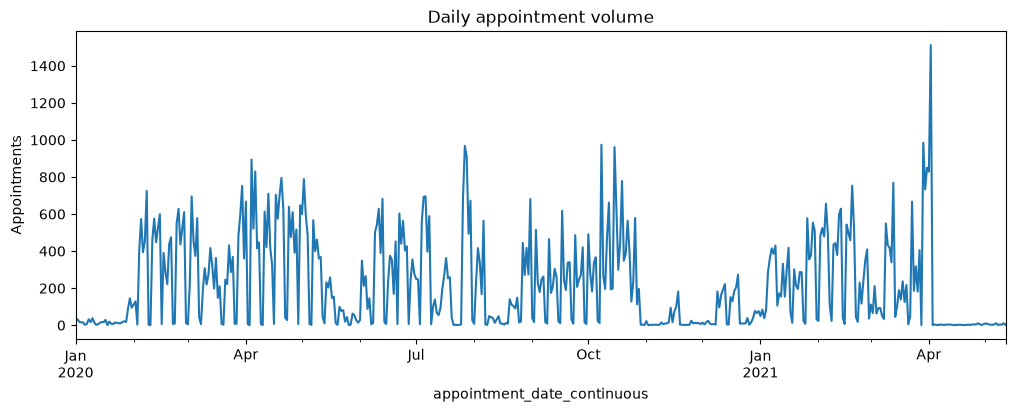

In [2]:
daily["appointments"].plot(figsize=(12, 4))
plt.title("Daily appointment volume")
plt.ylabel("Appointments")
plt.show()

Cell 1: load and count appointments per day

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/clean.csv", parse_dates=["appointment_date_continuous"])

daily = (df.groupby("appointment_date_continuous").size()
           .rename("appointments").to_frame())
print(daily.shape)
daily.describe()

(498, 1)


,appointments
count,498.000000
mean,220.066265
std,245.803633
min,1.000000
25%,10.000000
50%,126.500000
75%,393.250000
max,1512.000000
